In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import fetch_openml

In [ ]:

# Import the MNIST dataset. this might be slow
X,y = fetch_openml('mnist_784',
 return_X_y=True)

In [ ]:
n_images = X.shape[0]

# Convert data to numpy image pixel-by-pixel representation
X_images = X.to_numpy().reshape(n_images, 28, 28)

# Flatten the data so that we can apply clustering
X_flat = X_images.reshape(n_images, 28 * 28)

In [ ]:
print(X.shape, X_flat.shape, X_images.shape, y.shape)
X_images[0]

(70000, 784) (70000, 784) (70000, 28, 28) (70000,)


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

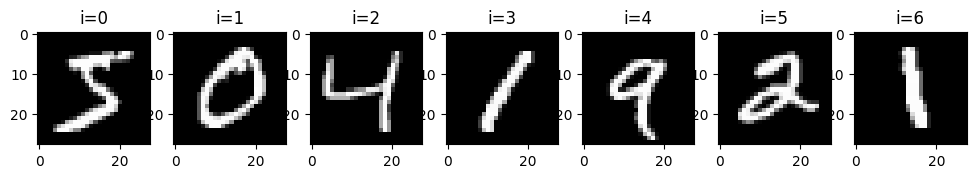

In [ ]:
# plot the resulting images
plt.figure(figsize=(12, 12))
img_max = 7
for i in range(img_max):
    ax = plt.subplot(img_max, img_max, i + 1)
    plt.imshow(X_images[i,:], cmap=plt.cm.gray)
    ax.set_title(f"i={i}")


See if the elbow plot is useful. Is there an elbow at k = 10? This will be slow because it has to chug through a lot of images.

In [ ]:
inertia = []
for k in range(7 , 14): # this is slow
    algorithm = (KMeans(n_clusters = k ,init='k-means++', n_init = 10 ,max_iter=100,
                        tol=0.0001,  random_state= 111  , algorithm='elkan') )
    algorithm.fit(X_flat)
    inertia.append(algorithm.inertia_)

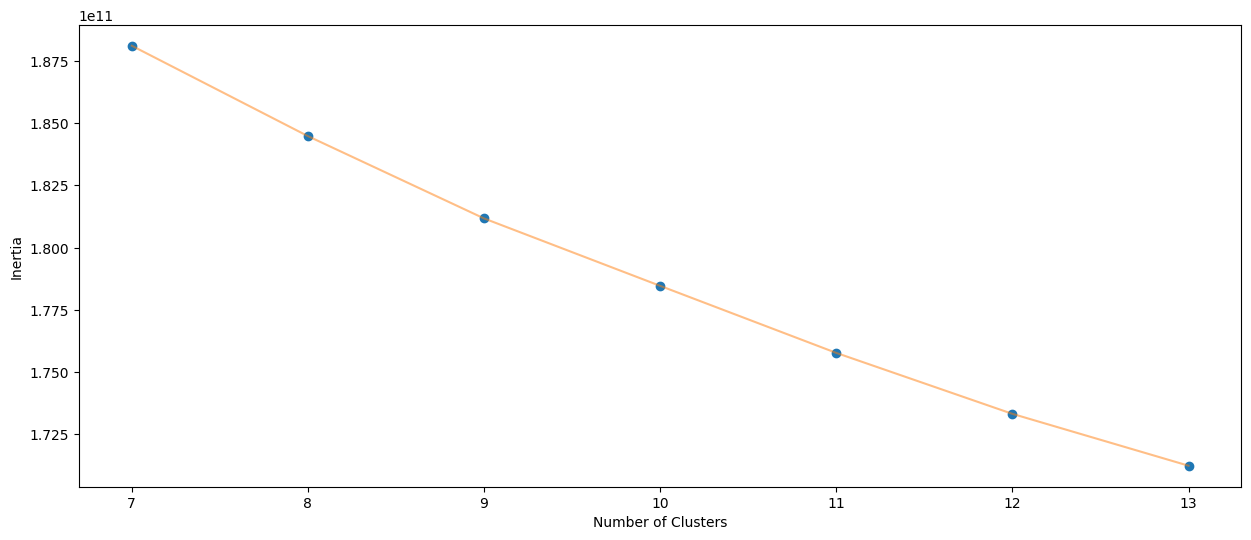

In [7]:
plt.figure(1 , figsize = (15 ,6))
plt.plot(np.arange(7 , 14) , inertia , 'o')
plt.plot(np.arange(7 , 14) , inertia , '-' , alpha = 0.5)
plt.xlabel('Number of Clusters') , plt.ylabel('Inertia')
plt.show()

Since k-means calculates the location of the centroid (which can be interpreted as the 'average' image), we can plot these centroids as images.

### Plotting Code
We are going to be needing plotting code a lot, so we'll encapsulate into a function.




In [8]:
def cluster_and_plot(X_flat, n_clusters):
    algorithm = (KMeans(n_clusters = n_clusters ,init='k-means++', n_init = 10 ,max_iter=100,
                            tol=0.0001,  random_state= 111  , algorithm='elkan') )
    algorithm.fit(X_flat)
    labels = algorithm.labels_
    centroids = algorithm.cluster_centers_

    fig, axes = plt.subplots(1, n_clusters)
    n_clusters = len(np.unique(labels))

    for c_i in range(n_clusters):
        # get center for cluster c_i and reshape it for plotting
        image = centroids[c_i].reshape(28,28)

        # plot the cluster centers
        axes[c_i].imshow(image, cmap='grey')
        axes[c_i].set_yticks([])
        axes[c_i].set_xticks([])
    return labels

# labels - the output of the clustering algorithm
# X_images - the original images in 28x28 pixel format
# n_clusters - the number of clusters in the clustering algorithm, such as 10 (the true value) or 13 (if you are being experimental)

def plot_images(labels, X_images, n_clusters):
    image_cluster = [[] for _ in range(n_clusters)]
    # Collect all images that belong to each cluster. j ranges over the cluster labels (0-9)
    img_max = 300
    for j in range(n_clusters):
        for i in range(img_max):
            if labels[i] == j:  # Only collect images that belong to the current cluster
                image_cluster[j].append(X_images[i, :])
            if len(image_cluster[j]) >= 13:  # Limit to 10 images per cluster
                break

    for n in range(len(image_cluster)):
        k = len(image_cluster[n])
        fig, axes = plt.subplots(1, k, figsize=(1 * k, 1), squeeze=False)
        for i, ax in enumerate(axes[0]):
            ax.imshow(image_cluster[n][i], cmap=plt.cm.gray)
            ax.set_title(f"Cluster{n}")
            ax.axis("off")
        plt.show()

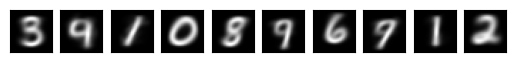

In [9]:
n_clusters = 10
labels = cluster_and_plot(X_flat , n_clusters)

Looking at the averages, we can see what the numbers are supposed to be, mostly. Unfortunately, the fours, nines and sevens look hard to distinguish, and there's no 5 - it looks like it got added into the 8.


We can get a sense of what happened by looking at individual images.

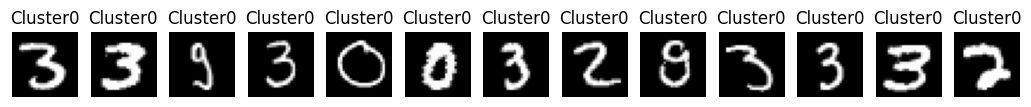

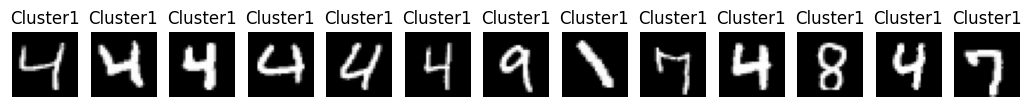

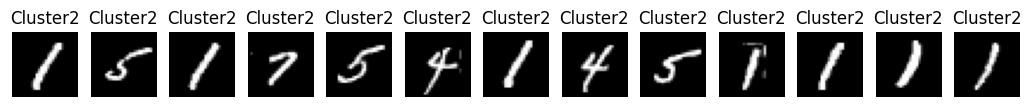

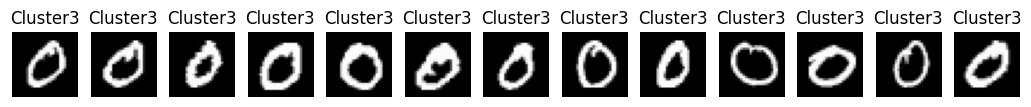

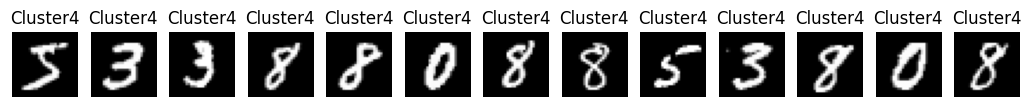

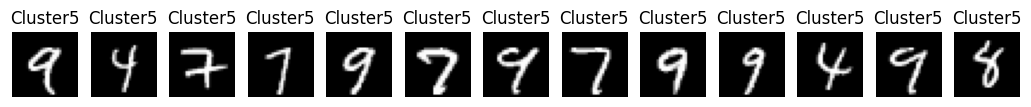

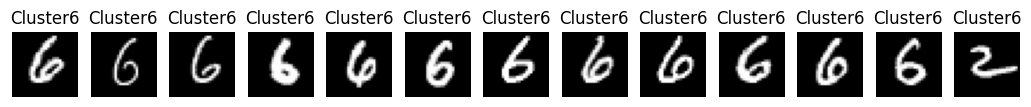

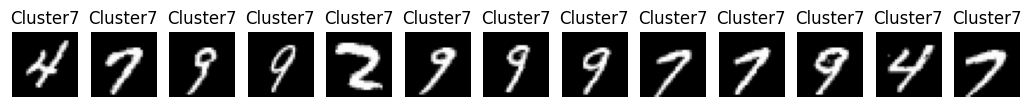

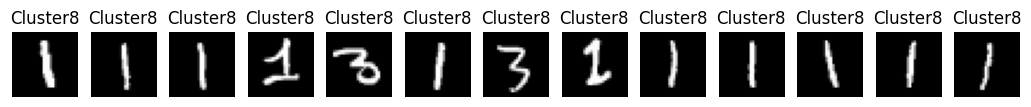

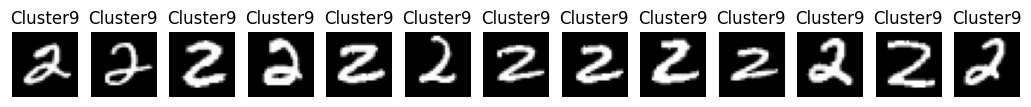

In [10]:
plot_images(labels, X_images, 10)

Looking at the images, we can try to assign numerical labels to each cluster. In some cases, this is tricky, but I'm going to say the Cluster2 is the 5 cluster because there's not really any other 5 candidate. So then my best guess at labels is:

In [11]:
cluster_labels = [3,4, 5, 0, 8, 7, 6, 9, 1, 2]  #REASSIGN THESE AS NEEDED TO MATCH YOUR OBSERVATIONS from the above plots
n_clusters = 10


# calculate accuracy by comparing the cluster labels to the true labels
def calculate_accuracy(labels, y, cluster_labels, n_clusters):
  count = 0
  for i in range(len(labels)):
    labeled = cluster_labels[labels[i]]
    actual = y[i]
    if int(actual) == int(labeled):
      count +=1
  return count/(len(labels))

calculate_accuracy(labels, y, cluster_labels, n_clusters)

0.5222428571428571

My results were pretty appalling.

For fun, let's see what happens if we let it use 13 clusters. Will it use the extra clusters in a logical way, like finding different ways people write their 7's?

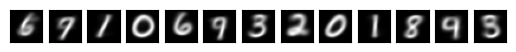

In [12]:
n_clusters = 13
labels = cluster_and_plot(X_flat, n_clusters)


In [13]:
cluster_labels = [6,7,1, 0, 6, 9, 3, 2, 0, 1, 8, 4, 5] #REASSIGN THESE AS NEEDED TO MATCH YOUR OBSERVATIONS. I got 60% accuracy here.
calculate_accuracy(labels, y, cluster_labels, n_clusters)

0.6085142857142857

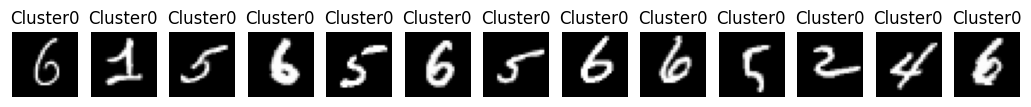

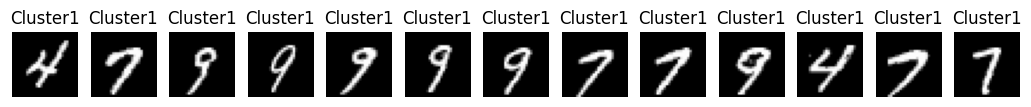

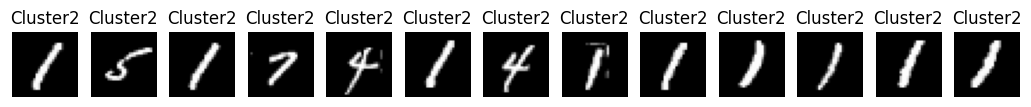

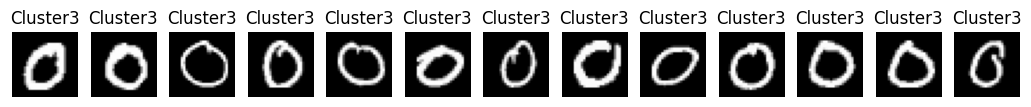

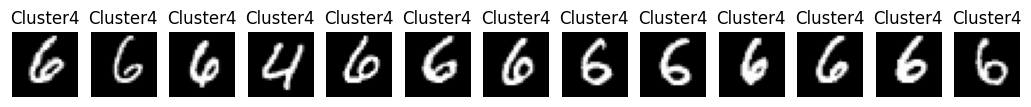

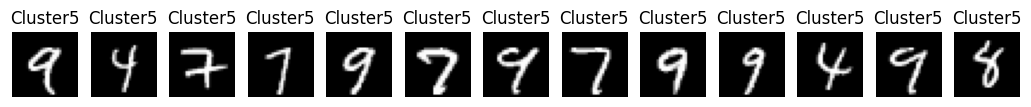

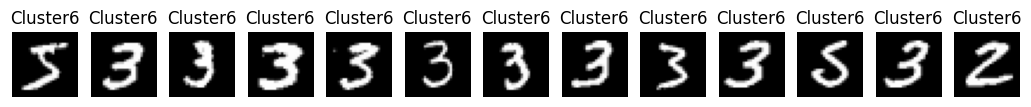

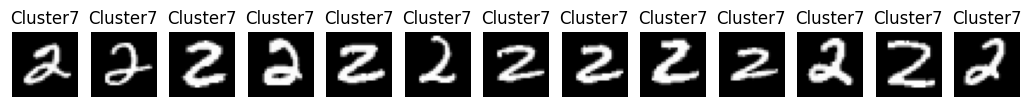

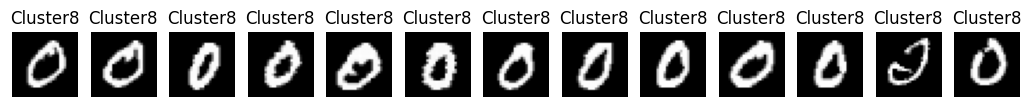

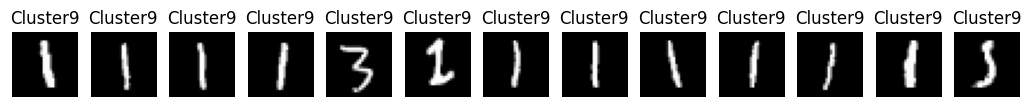

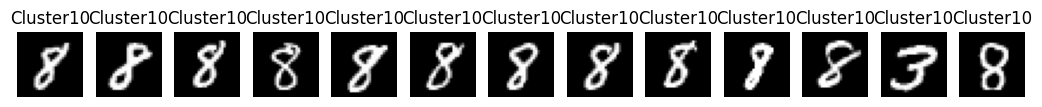

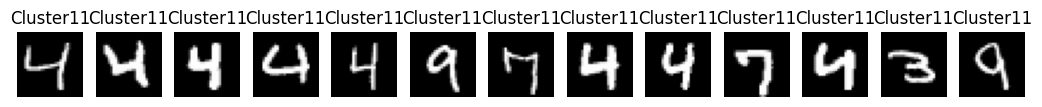

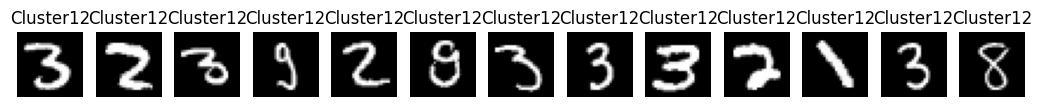

In [ ]:
plot_images(labels, X_images, n_clusters )

## Alternate method: HDBScan

Density-based clustering method. First, rescale data and reduce dimensions. Install umap-learn first.

In [15]:
import umap  # pip install umap-learn is the installation command
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.manifold import TSNE
from sklearn.cluster import HDBSCAN

# takes about one minute to run

# reload mnist as a numpy array this time
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)
X_subset = X[:10000] / 255.0  # Normalize pixels

# reduce dimensions with  umap
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1)
X_red = reducer.fit_transform(X_subset)

This is our main algorithm. It's a density-based method.

In [16]:
algorithm = HDBSCAN(min_cluster_size=100, min_samples=10).fit(X_red) # these are parameters that can be tuned to get better results.
labels = algorithm.labels_

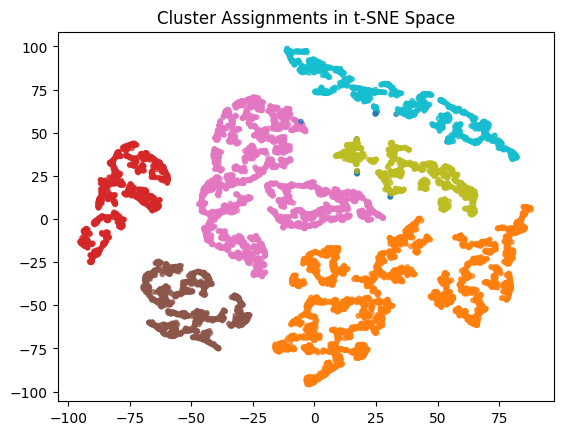

In [17]:
#  Reduce dimensions to 2D using t-SNE for visualization - takes 20 seconds
tsne = TSNE(n_components=2, random_state=1)
X_2d = tsne.fit_transform(X_red)
# Plot cluster Assignments
scatter1 = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='tab10', s=10, alpha=0.7)
plt.title("Cluster Assignments in t-SNE Space")
plt.show()

This only looks like 6 clusters, though! We can check the cluster counts:

In [18]:
image_counts = [0 for _ in range(10)]
for j in range(10):
    for i in range(len(labels)):
        if labels[i] == j:  # Only collect images that belong to the current cluster
            image_counts[j]+=1
print(image_counts)

[3045, 1021, 1043, 2724, 932, 1218, 0, 0, 0, 0]


In [19]:
n_images = X.shape[0]

# Convert data to numpy image pixel-by-pixel representation
X_images = X.reshape(n_images, 28, 28)

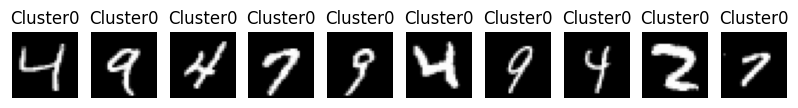

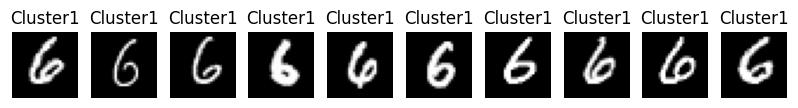

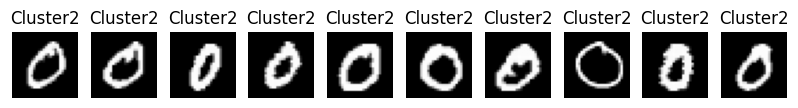

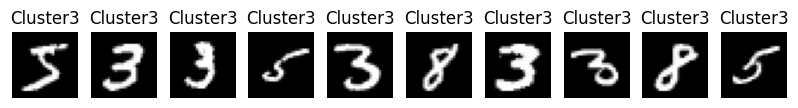

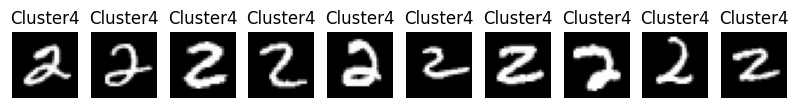

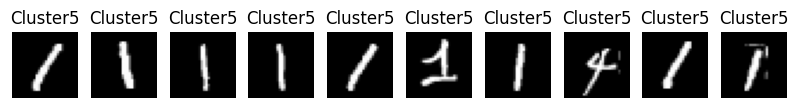

In [32]:
image_cluster = [[] for _ in range(10)]
# Collect all images that belong to each cluster. j ranges over the cluster labels (0-9)
img_max = 300
for j in range(10):
    for i in range(img_max):
        if labels[i] == j:  # Only collect images that belong to the current cluster
            image_cluster[j].append(X_images[i, :])
def plot_images(labels, X_images, n_clusters):
    image_cluster = [[] for _ in range(n_clusters)]
    # Collect all images that belong to each cluster. j ranges over the cluster labels (0-9)
    for j in range(n_clusters):
        for i in range(img_max):
            if labels[i] == j:  # Only collect images that belong to the current cluster
                image_cluster[j].append(X_images[i, :])
            if len(image_cluster[j]) >= 10:  # Limit to 10 images per cluster
                break

    for n in range(len(image_cluster)):
        k = len(image_cluster[n])
        if k!= 0:
            fig, axes = plt.subplots(1, k, figsize=(1 * k, 1), squeeze=False)
            for i, ax in enumerate(axes[0]):
                ax.imshow(image_cluster[n][i], cmap=plt.cm.gray)
                ax.set_title(f"Cluster{n}")
                ax.axis("off")
            plt.show()
plot_images(labels, X_images, 10)

Calculate the accuracy after manually assigning the cluster labels.

In [29]:
cluster_labels = [4, 6, 0, 3, 2, 1]
number_of_clusters = len(cluster_labels)
calculate_accuracy(labels, y, cluster_labels, len(cluster_labels))

0.5941

# Analysis and Conclusions
## Write your answers here
What happens to accuracy when you increase k in the k-means approach?
It improves the accuracy, probably because the different ways of writing numbers are clustered separately so there's less confusion.

Compare the accuracy of the two different clustering algorithms (for a given value of k).
The second method gave an accuracy of 0.59, which was really close to the k means accuracy when k was 10, which was 0.61.